In [1]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 
import warnings 
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import LabelEncoder,StandardScaler

from sklearn.linear_model import Perceptron    # Used for simple linear classification tasks.

from sklearn.metrics import accuracy_score , confusion_matrix , classification_report
from tensorflow.keras.models import Sequential  # Sequential lets you build a neural network layer-by-layer in Keras.
from tensorflow.keras.layers import Dense       # Dense makes the final predictions
from tensorflow.keras.layers import Conv2D      # Conv2D extracts features
from tensorflow.keras.layers import Flatten     # Flatten reshapes them
from tensorflow.keras.layers import MaxPooling2D    # MaxPooling2D reduces size
from tensorflow.keras.layers import Dropout          # Dropout prevents overfitting
from tensorflow.keras.utils import to_categorical     # converts numeric class labels into one-hot encoded format for training classification models
     


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.3 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\LENOVO\AppData\Roaming\Python\Python312\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\LENOVO\AppData\Roaming\Python\Python312\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "C:\Users\LENOVO\AppData\Roaming\Python\Python312\site-packages\ipykernel\kernelapp.py", line 758, in start
    self.io

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.3 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\LENOVO\AppData\Roaming\Python\Python312\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\LENOVO\AppData\Roaming\Python\Python312\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "C:\Users\LENOVO\AppData\Roaming\Python\Python312\site-packages\ipykernel\kernelapp.py", line 758, in start
    self.io

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.3 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



In [2]:
df=pd.read_csv("mnist_train.csv")
df_test=pd.read_csv("mnist_test.csv")

In [3]:
df.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [4]:
df.shape

(42000, 785)

In [5]:
df.columns

Index(['label', 'pixel0', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5',
       'pixel6', 'pixel7', 'pixel8',
       ...
       'pixel774', 'pixel775', 'pixel776', 'pixel777', 'pixel778', 'pixel779',
       'pixel780', 'pixel781', 'pixel782', 'pixel783'],
      dtype='object', length=785)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Columns: 785 entries, label to pixel783
dtypes: int64(785)
memory usage: 251.5 MB


In [7]:
df.isnull().sum()

label       0
pixel0      0
pixel1      0
pixel2      0
pixel3      0
           ..
pixel779    0
pixel780    0
pixel781    0
pixel782    0
pixel783    0
Length: 785, dtype: int64

In [8]:
# preprocess 

x_train=df.drop("label",axis=1).values 
y_train=df["label"].values
x_test=df_test.drop("label",axis=1).values 
y_test=df_test["label"].values

In [9]:
x_train = x_train.astype('float32')/255.0 
x_test = x_test.astype('float32')/255.0

In [10]:
x_train_img=x_train.reshape(-1,28,28)
x_test_img=x_test.reshape(-1,28,28)

In [11]:
y_train_cat= to_categorical(y_train,10)
y_test_cat=to_categorical(y_test,10)

In [12]:
perceptron=Sequential([
    Flatten(input_shape=(28,28)),
    Dense(10,activation="softmax")
])

In [13]:
perceptron.compile(optimizer="sgd",loss="categorical_crossentropy",metrics=["accuracy"])

In [14]:
history_percp=perceptron.fit(x_train_img,y_train_cat,epochs=5,batch_size=32,validation_data=(x_test_img,y_test_cat),verbose=1)

Epoch 1/5
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.7919 - loss: 0.8825 - val_accuracy: 0.8642 - val_loss: 0.5593
Epoch 2/5
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.8734 - loss: 0.4987 - val_accuracy: 0.8814 - val_loss: 0.4550
Epoch 3/5
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.8859 - loss: 0.4321 - val_accuracy: 0.8901 - val_loss: 0.4113
Epoch 4/5
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.8920 - loss: 0.3992 - val_accuracy: 0.8950 - val_loss: 0.3866
Epoch 5/5
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.8963 - loss: 0.3787 - val_accuracy: 0.8992 - val_loss: 0.3693


In [15]:
acc_percp=perceptron.evaluate(x_test_img,y_test_cat,verbose=0)[1]

In [16]:
acc_percp

0.8991666436195374

In [17]:
# ANN 
ann=Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128,activation="relu"),
    Dense(64,activation="relu"),
    Dense(10,activation="softmax")
])

In [18]:
ann.compile(optimizer="adam",loss="categorical_crossentropy",metrics=["accuracy"])

In [19]:
history_ann=ann.fit(x_train_img,y_train_cat,epochs=5,batch_size=32,validation_data=(x_test_img,y_test_cat),verbose=1)

Epoch 1/5
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.9219 - loss: 0.2706 - val_accuracy: 0.9637 - val_loss: 0.1240
Epoch 2/5
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.9661 - loss: 0.1127 - val_accuracy: 0.9801 - val_loss: 0.0698
Epoch 3/5
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.9765 - loss: 0.0758 - val_accuracy: 0.9858 - val_loss: 0.0487
Epoch 4/5
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.9813 - loss: 0.0574 - val_accuracy: 0.9887 - val_loss: 0.0374
Epoch 5/5
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.9863 - loss: 0.0428 - val_accuracy: 0.9886 - val_loss: 0.0344


In [20]:
acc_ann=ann.evaluate(x_test_img,y_test_cat,verbose=0)[1]
acc_ann

0.9885952472686768

In [21]:
#CNN 
x_train_cnn=x_train.reshape(-1,28,28,1)
x_test_cnn=x_test.reshape(-1,28,28,1)

In [22]:
cnn=Sequential([
    Conv2D(32,kernel_size=(3,3),activation="relu",input_shape=(28,28,1)),
    MaxPooling2D(pool_size=(2,2)),
    Conv2D(64,kernel_size=(3,3),activation="relu"),
    MaxPooling2D(pool_size=(2,2)),
    Flatten(),
    Dense(128,activation="relu"),
    Dropout(0.5),
    Dense(10,activation="softmax")
    
])

In [23]:
cnn.compile(optimizer="adam",loss="categorical_crossentropy",metrics=["accuracy"])

In [24]:
history_cnn=cnn.fit(x_train_cnn,y_train_cat,epochs=5,batch_size=32,validation_data=(x_test_cnn,y_test_cat),verbose=1)

Epoch 1/5
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 37s 27ms/step - accuracy: 0.9281 - loss: 0.2378 - val_accuracy: 0.9835 - val_loss: 0.0549
Epoch 2/5
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 36s 27ms/step - accuracy: 0.9743 - loss: 0.0877 - val_accuracy: 0.9897 - val_loss: 0.0346
Epoch 3/5
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 36s 28ms/step - accuracy: 0.9812 - loss: 0.0652 - val_accuracy: 0.9923 - val_loss: 0.0249
Epoch 4/5
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 31s 24ms/step - accuracy: 0.9851 - loss: 0.0506 - val_accuracy: 0.9937 - val_loss: 0.0197
Epoch 5/5
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 39s 30ms/step - accuracy: 0.9866 - loss: 0.0449 - val_accuracy: 0.9950 - val_loss: 0.0157


In [25]:
acc_cnn=cnn.evaluate(x_test_cnn,y_test_cat,verbose=0)[1]
acc_cnn

0.9950476288795471

In [31]:
def plot_training(history,title):
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.plot(history.history['accuracy'],label="Train")
    plt.plot(history.history['val_accuracy'],label="Val")
    plt.title(f"{title} Accuracy")
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(history.history['loss'],label="Train")
    plt.plot(history.history['val_loss'],label="Val")
    plt.title(f"{title} Loss")
    plt.legend()
    plt.show()

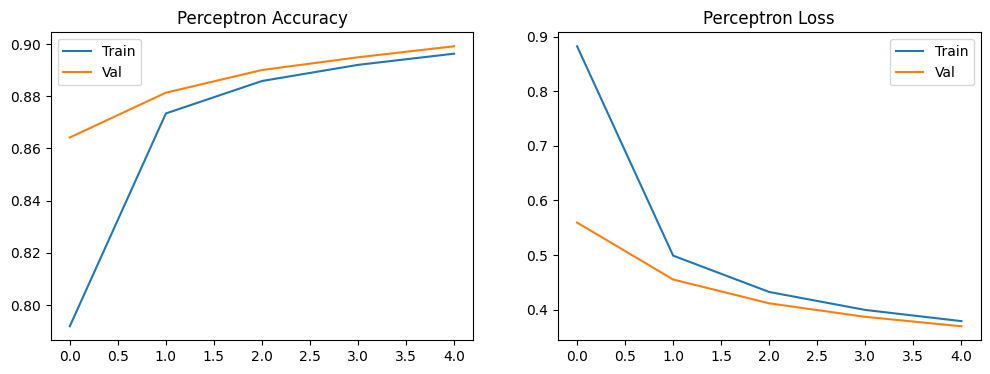

In [32]:
plot_training(history_percp,"Perceptron")

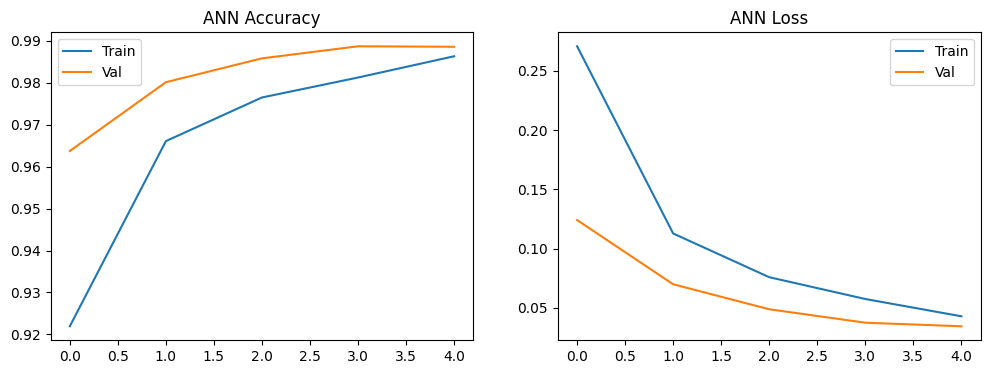

In [33]:
plot_training(history_ann,"ANN")

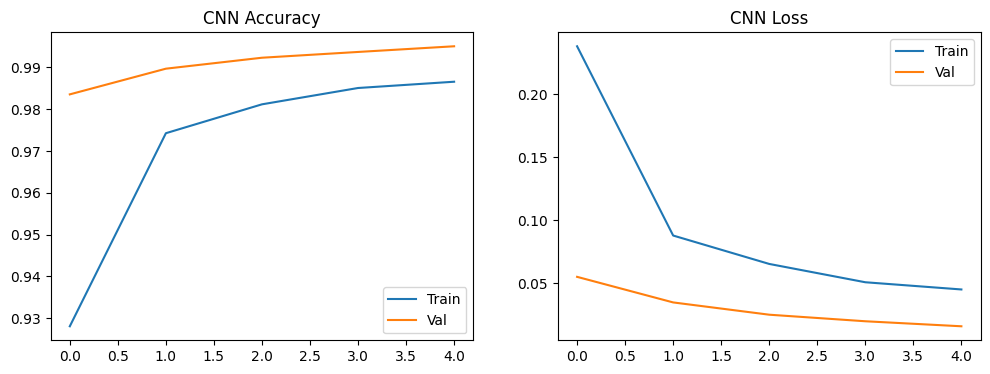

In [34]:
plot_training(history_cnn,"CNN")

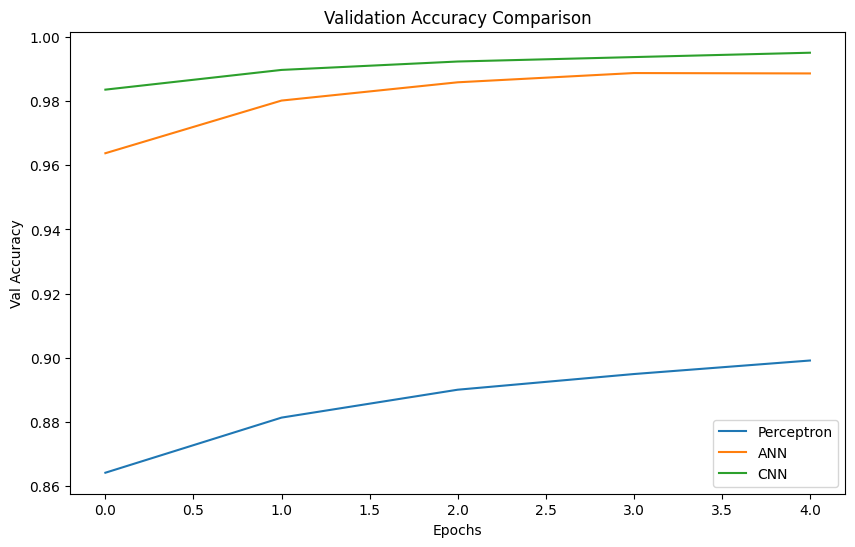

In [35]:
    plt.figure(figsize=(10,6))
    plt.plot(history_percp.history['val_accuracy'],label="Perceptron")
    plt.plot(history_ann.history['val_accuracy'],label="ANN")
    plt.plot(history_cnn.history['val_accuracy'],label="CNN")
    plt.title("Validation Accuracy Comparison")
    plt.xlabel("Epochs")
    plt.ylabel("Val Accuracy")
    plt.legend()
    plt.show()

In [43]:
def show_side_by_side(models,model_names,x,x_cnn,y_true,n=5):
    idxs=np.random.choice(len(x),n , replace=False)
    plt.figure(figsize=(15,6))
    for i, idx in enumerate(idxs):
        plt.subplot(2,n,i+1)
        plt.imshow(x[idx].reshape(28,28),cmap="gray")
        plt.axis("off")
        plt.title(f"True:{y_true[idx]}")
        preds=[np.argmax(model.predict(x_cnn[idx].reshape(1,28,28,1) if name == "CNN" else x[idx].reshape(1,28,28,1)))
                                for model,name in zip(models,model_names)] 
        plt.subplot(2,n,n+i+1)
        plt.axis("off")
        plt.title("\n".join(f"{n}:{p}" for n, p  in zip(model_names,preds)))
    plt.tight_layout()
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step


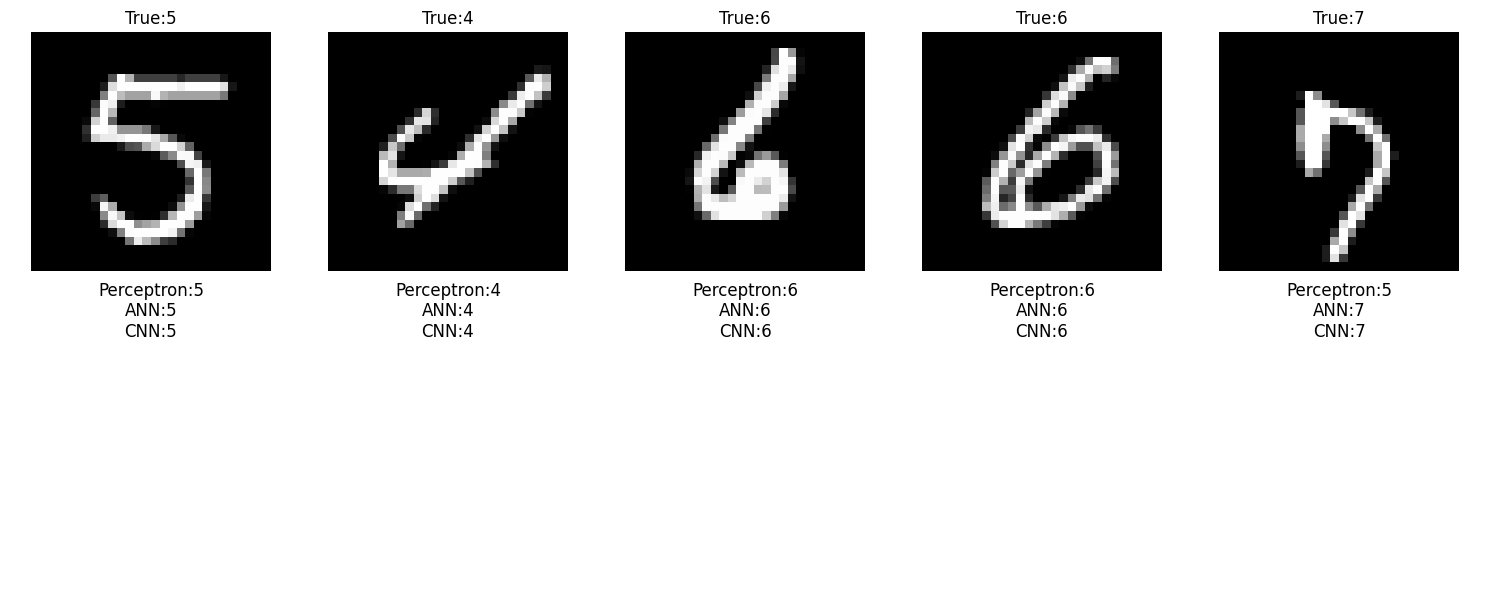

In [44]:
show_side_by_side([perceptron,ann,cnn],["Perceptron","ANN","CNN"],
x_test_img,x_test_cnn,y_test,5)

1313/1313 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step


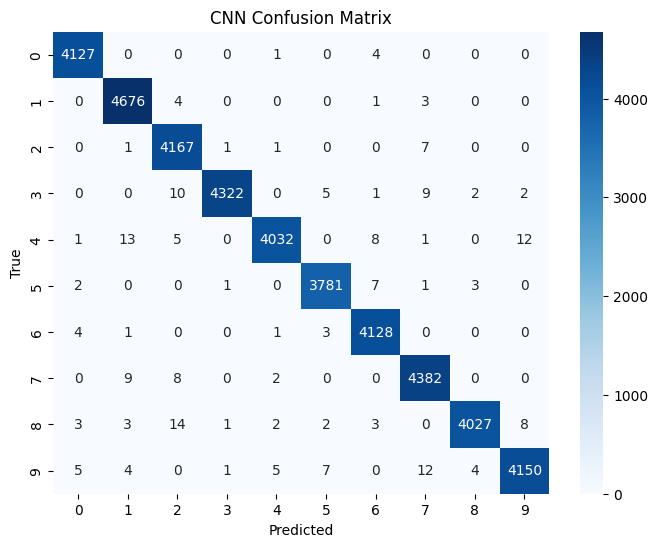

In [46]:
y_pred_cnn = np.argmax(cnn.predict(x_test_cnn), axis=1)
cm = confusion_matrix(y_test, y_pred_cnn)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

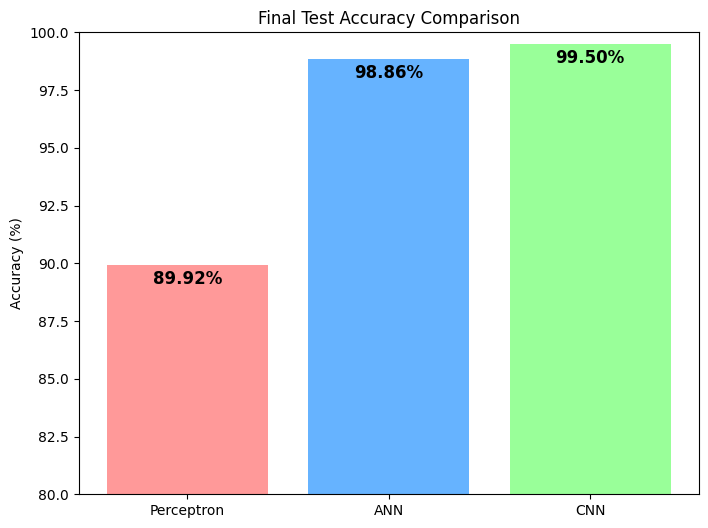

In [47]:
final_accs = [acc_percp*100, acc_ann*100, acc_cnn*100]
models = ["Perceptron", "ANN", "CNN"]

plt.figure(figsize=(8,6))
bars = plt.bar(models, final_accs, color=['#ff9999','#66b3ff','#99ff99'])
plt.title("Final Test Accuracy Comparison")
plt.ylabel("Accuracy (%)")
for bar, acc in zip(bars, final_accs):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()-1, f"{acc:.2f}%",
             ha='center', va='bottom', fontsize=12, fontweight='bold')
plt.ylim(80, 100)
plt.show()